# Self-Organizing Maps (SOMs) Notebook - Alaska Cyclones
- Plot regional T2m by latitude and decade to see where maximum baroclinicity is changing

**Notebook by Alice DuVivier - July 2026**

In [1]:
import pandas as pd
import xarray as xr
import cftime
import numpy as np
import pandas as pd
from itertools import product
import cartopy
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from datetime import timedelta
from itertools import product
import cmocean
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.ticker as mtick

## Load data
- regional, monthly data by decade

In [2]:
# set path where the som finalist files are
dir_in = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/DATA/SOM_alaska_cyclones/data_for_composites/'

In [3]:
# Load data for larger area than only training area - set file name
var_in = 'TREFHT'
fin = var_in+'_monthly_autumn_decadal_alaska_cam_grid.nc'

# load data
ds = xr.open_dataset(dir_in+fin)

# explicitly load data so that it doesn't take forever later on during mean
ds = ds.load()

# keep only the variable of interest
ds = ds[var_in]

# convert from K to C
ds = ds - 273.15
units = 'C'

In [4]:
# set lat/lon
lat1d = ds.lat
lon1d = ds.lon

## Get data along one longitude
- Find a longitude to examine. 170W is mostly over ocean, which is 191.625 on the 0-360 grid

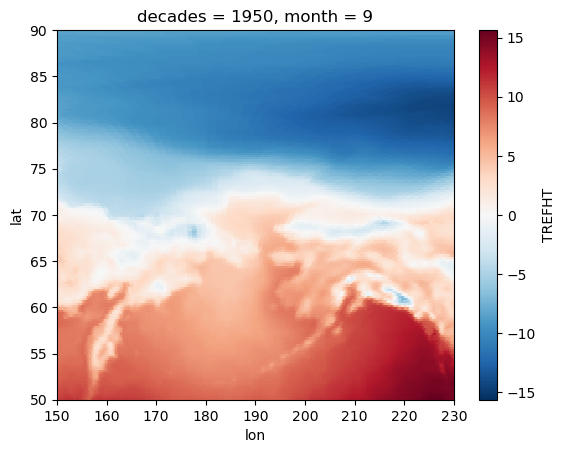

In [5]:
ds.isel(decades=0,ensemble=0,month=0).plot()

In [6]:
ds.lon.values

array([150.125, 150.375, 150.625, 150.875, 151.125, 151.375, 151.625,
       151.875, 152.125, 152.375, 152.625, 152.875, 153.125, 153.375,
       153.625, 153.875, 154.125, 154.375, 154.625, 154.875, 155.125,
       155.375, 155.625, 155.875, 156.125, 156.375, 156.625, 156.875,
       157.125, 157.375, 157.625, 157.875, 158.125, 158.375, 158.625,
       158.875, 159.125, 159.375, 159.625, 159.875, 160.125, 160.375,
       160.625, 160.875, 161.125, 161.375, 161.625, 161.875, 162.125,
       162.375, 162.625, 162.875, 163.125, 163.375, 163.625, 163.875,
       164.125, 164.375, 164.625, 164.875, 165.125, 165.375, 165.625,
       165.875, 166.125, 166.375, 166.625, 166.875, 167.125, 167.375,
       167.625, 167.875, 168.125, 168.375, 168.625, 168.875, 169.125,
       169.375, 169.625, 169.875, 170.125, 170.375, 170.625, 170.875,
       171.125, 171.375, 171.625, 171.875, 172.125, 172.375, 172.625,
       172.875, 173.125, 173.375, 173.625, 173.875, 174.125, 174.375,
       174.625, 174.

In [7]:
# longitude 190 is basically all over the ocean, so use 191.625
lon_keep = 191.625

ds_sub = ds.where(ds.lon == lon_keep, drop=True).isel(lon=0)

In [8]:
# subset by month
ds_sub_sep = ds_sub.where(ds_sub.month == 9, drop=True)
ds_sub_oct = ds_sub.where(ds_sub.month == 10, drop=True)
ds_sub_nov = ds_sub.where(ds_sub.month == 11, drop=True)
ds_sub_dec = ds_sub.where(ds_sub.month == 12, drop=True)

### Calculate ensemble means by month

In [9]:
# calculate ensemble means for each decade
ds_sep_avg = ds_sub_sep.mean(dim=['ensemble', 'month'])
ds_oct_avg = ds_sub_oct.mean(dim=['ensemble', 'month'])
ds_nov_avg = ds_sub_nov.mean(dim=['ensemble', 'month'])
ds_dec_avg = ds_sub_dec.mean(dim=['ensemble', 'month'])

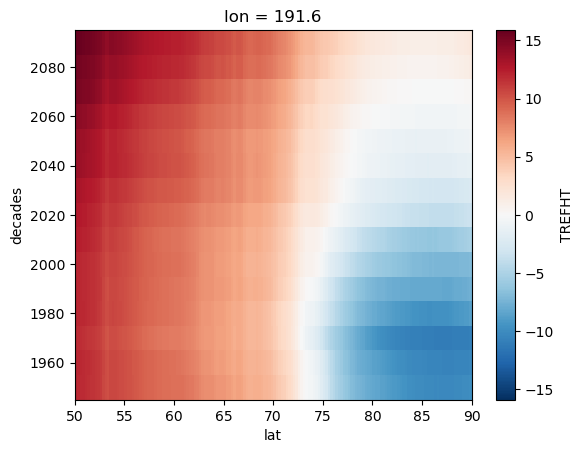

In [10]:
ds_sep_avg.plot()

### Calculate latitudinal gradients by month

In [11]:
# calculate gradients
ds_sep_grad = ds_sep_avg.differentiate("lat")
ds_oct_grad = ds_oct_avg.differentiate("lat")
ds_nov_grad = ds_nov_avg.differentiate("lat")
ds_dec_grad = ds_dec_avg.differentiate("lat")

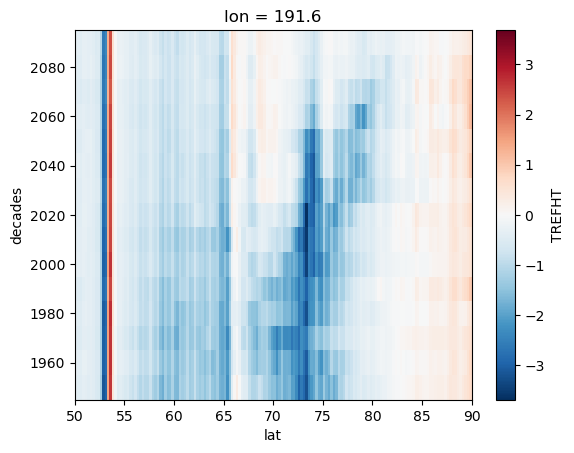

In [12]:
ds_dec_grad.plot()

### Smooth the temperature and gradients in the latitude dimension
- Want to reduce some of the noise

In [13]:
# smooth the temperatures by 5 points (roughly 1degree), centered
#npts = 5
npts = 10

ds_sep_avg_smooth = ds_sep_avg.rolling(lat=npts, center=True).mean()
ds_oct_avg_smooth = ds_oct_avg.rolling(lat=npts, center=True).mean()
ds_nov_avg_smooth = ds_nov_avg.rolling(lat=npts, center=True).mean()
ds_dec_avg_smooth = ds_dec_avg.rolling(lat=npts, center=True).mean()

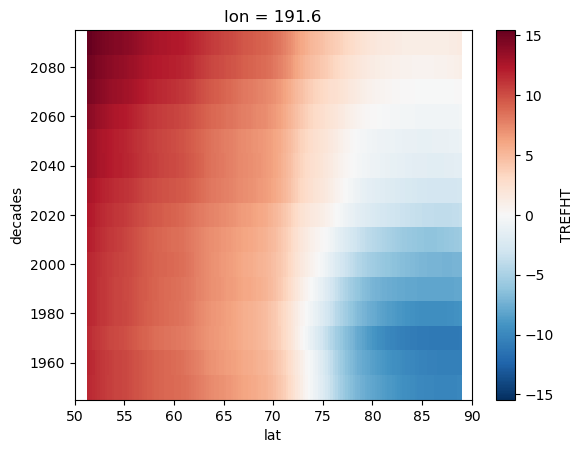

In [14]:
ds_sep_avg_smooth.plot()

In [15]:
# now calculate gradients of the smoothed temperatures
ds_sep_grad_smooth = ds_sep_avg_smooth.differentiate("lat")
ds_oct_grad_smooth = ds_oct_avg_smooth.differentiate("lat")
ds_nov_grad_smooth = ds_nov_avg_smooth.differentiate("lat")
ds_dec_grad_smooth = ds_dec_avg_smooth.differentiate("lat")

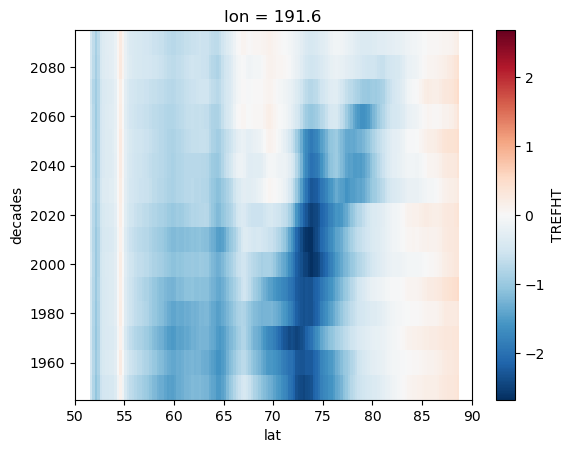

In [16]:
ds_dec_grad_smooth.plot()

## Plot T2m values by decade

In [17]:
# set output directory
dir_out = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/SOM_alaska_cyclones/analysis_v3/'

In [18]:
# set the decades
decades = ds_sep_avg.decades
ndec = len(decades)

In [19]:
# set xarray to plot against
xarr_lat = ds_sep_avg.lat

In [20]:
# set colors
cmap = plt.get_cmap('viridis')
colors = cmap(np.linspace(0, 1, len(decades)))

### Plot mean temperatures along transect

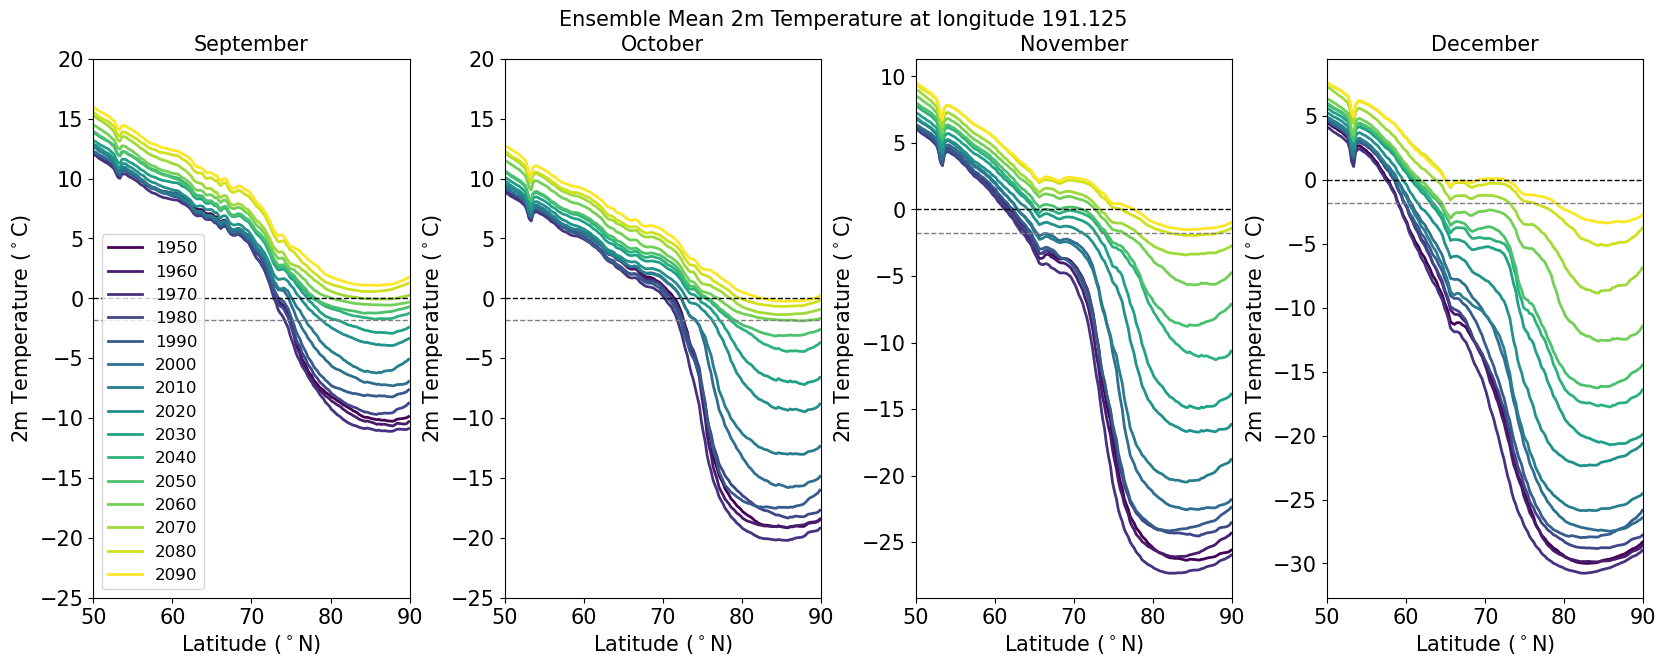

In [21]:
# create figure
fig = plt.figure(figsize=(20,7))
# now loop through months to create subpanels
fout = 'supp_decadal_T2m_along_longitude_transect'

### Sept subplot
ax = fig.add_subplot(1,4,1)
# plot the decadal means
for dd in range(ndec):
    ax.plot(xarr_lat,ds_sep_avg.isel(decades=dd),color=colors[dd],linestyle='-',linewidth=2,label=str(decades[dd].values));
ax.axhline(y=0, color='black', linestyle='--', linewidth=1)
ax.axhline(y=-1.8, color='grey', linestyle='--', linewidth=1)
# modify plot
plt.title('September',fontsize=15)
plt.xlabel(r'Latitude ($^\circ$N)',fontsize=15)
plt.xticks(fontsize=15)
plt.xlim([50,90])
plt.ylabel(r'2m Temperature ($^\circ$C)',fontsize=15)
plt.yticks(fontsize=15)
plt.ylim([-25,20])
plt.legend(loc='lower left', fontsize=12, ncol=1)

### Oct subplot
ax = fig.add_subplot(1,4,2)
# plot the decadal means
for dd in range(ndec):
    ax.plot(xarr_lat,ds_oct_avg.isel(decades=dd),color=colors[dd],linestyle='-',linewidth=2,label=str(decades[dd].values));
ax.axhline(y=0, color='black', linestyle='--', linewidth=1)
ax.axhline(y=-1.8, color='grey', linestyle='--', linewidth=1)
# modify plot
plt.title('October',fontsize=15)
plt.xlabel(r'Latitude ($^\circ$N)',fontsize=15)
plt.xticks(fontsize=15)
plt.xlim([50,90])
plt.ylabel(r'2m Temperature ($^\circ$C)',fontsize=15)
plt.yticks(fontsize=15)
plt.ylim([-25,20])
#plt.legend(loc='upper right', fontsize=12, ncol=3)

### Nov subplot
ax = fig.add_subplot(1,4,3)
# plot the decadal means
for dd in range(ndec):
    ax.plot(xarr_lat,ds_nov_avg.isel(decades=dd),color=colors[dd],linestyle='-',linewidth=2,label=str(decades[dd].values));
ax.axhline(y=0, color='black', linestyle='--', linewidth=1)
ax.axhline(y=-1.8, color='grey', linestyle='--', linewidth=1)
# modify plot
plt.title('November',fontsize=15)
plt.xlabel(r'Latitude ($^\circ$N)',fontsize=15)
plt.xticks(fontsize=15)
plt.xlim([50,90])
plt.ylabel(r'2m Temperature ($^\circ$C)',fontsize=15)
plt.yticks(fontsize=15)
#plt.ylim([-25,20])
#plt.legend(loc='upper right', fontsize=12, ncol=3)

### Dec subplot
ax = fig.add_subplot(1,4,4)
# plot the decadal means
for dd in range(ndec):
    ax.plot(xarr_lat,ds_dec_avg.isel(decades=dd),color=colors[dd],linestyle='-',linewidth=2,label=str(decades[dd].values));
ax.axhline(y=0, color='black', linestyle='--', linewidth=1)
ax.axhline(y=-1.8, color='grey', linestyle='--', linewidth=1)
# modify plot
plt.title('December',fontsize=15)
plt.xlabel(r'Latitude ($^\circ$N)',fontsize=15)
plt.xticks(fontsize=15)
plt.xlim([50,90])
plt.ylabel(r'2m Temperature ($^\circ$C)',fontsize=15)
plt.yticks(fontsize=15)
#plt.ylim([-25,20])
#plt.legend(loc='lower left', fontsize=12, ncol=1)

# Finalize figure and save
#add title
fig.suptitle('Ensemble Mean 2m Temperature at longitude 191.125',fontsize=15, y=0.95)  
fig.subplots_adjust(wspace=0.3, hspace=0.2)
# save figure
fig = plt.savefig(fout+'.png', bbox_inches='tight', dpi=200)
fig = plt.savefig(dir_out+fout+'.png', bbox_inches='tight', dpi=200)

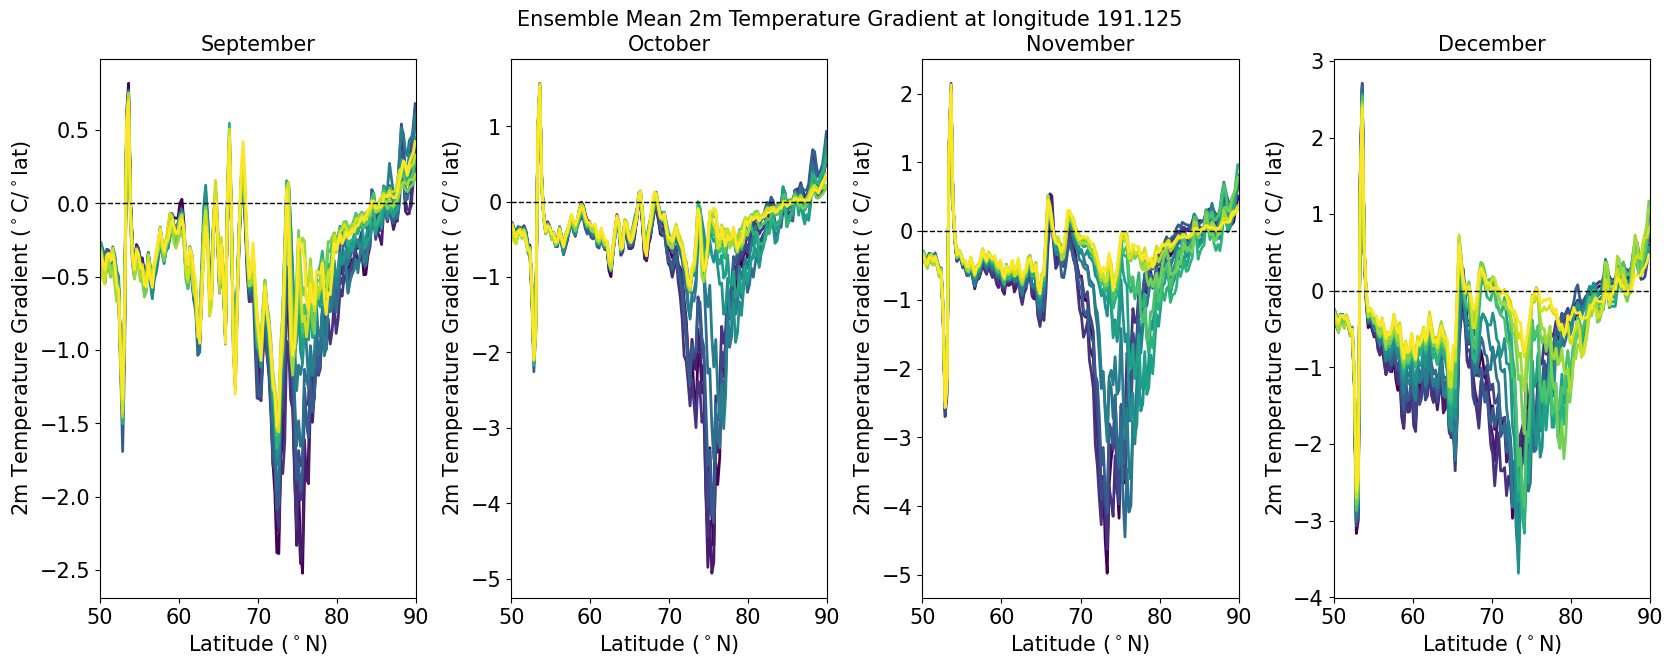

In [22]:
# create figure
fig = plt.figure(figsize=(20,7))
# now loop through months to create subpanels
fout = 'supp_decadal_T2m_gradient_along_longitude_transect'

### Sept subplot
ax = fig.add_subplot(1,4,1)
# plot the decadal means
for dd in range(ndec):
    ax.plot(xarr_lat,ds_sep_grad.isel(decades=dd),color=colors[dd],linestyle='-',linewidth=2,label=str(decades[dd].values));
ax.axhline(y=0, color='black', linestyle='--', linewidth=1)
# modify plot
plt.title('September',fontsize=15)
plt.xlabel(r'Latitude ($^\circ$N)',fontsize=15)
plt.xticks(fontsize=15)
plt.xlim([50,90])
plt.ylabel(r'2m Temperature Gradient ($^\circ$C/$^\circ$lat)',fontsize=15)
plt.yticks(fontsize=15)
#plt.legend(loc='lower left', fontsize=12, ncol=1)

### Oct subplot
ax = fig.add_subplot(1,4,2)
# plot the decadal means
for dd in range(ndec):
    ax.plot(xarr_lat,ds_oct_grad.isel(decades=dd),color=colors[dd],linestyle='-',linewidth=2,label=str(decades[dd].values));
ax.axhline(y=0, color='black', linestyle='--', linewidth=1)
# modify plot
plt.title('October',fontsize=15)
plt.xlabel(r'Latitude ($^\circ$N)',fontsize=15)
plt.xticks(fontsize=15)
plt.xlim([50,90])
plt.ylabel(r'2m Temperature Gradient ($^\circ$C/$^\circ$lat)',fontsize=15)
plt.yticks(fontsize=15)
#plt.legend(loc='upper right', fontsize=12, ncol=3)

### Nov subplot
ax = fig.add_subplot(1,4,3)
# plot the decadal means
for dd in range(ndec):
    ax.plot(xarr_lat,ds_nov_grad.isel(decades=dd),color=colors[dd],linestyle='-',linewidth=2,label=str(decades[dd].values));
ax.axhline(y=0, color='black', linestyle='--', linewidth=1)
# modify plot
plt.title('November',fontsize=15)
plt.xlabel(r'Latitude ($^\circ$N)',fontsize=15)
plt.xticks(fontsize=15)
plt.xlim([50,90])
plt.ylabel(r'2m Temperature Gradient ($^\circ$C/$^\circ$lat)',fontsize=15)
plt.yticks(fontsize=15)
#plt.legend(loc='upper right', fontsize=12, ncol=3)

### Dec subplot
ax = fig.add_subplot(1,4,4)
# plot the decadal means
for dd in range(ndec):
    ax.plot(xarr_lat,ds_dec_grad.isel(decades=dd),color=colors[dd],linestyle='-',linewidth=2,label=str(decades[dd].values));
ax.axhline(y=0, color='black', linestyle='--', linewidth=1)
# modify plot
plt.title('December',fontsize=15)
plt.xlabel(r'Latitude ($^\circ$N)',fontsize=15)
plt.xticks(fontsize=15)
plt.xlim([50,90])
plt.ylabel(r'2m Temperature Gradient ($^\circ$C/$^\circ$lat)',fontsize=15)
plt.yticks(fontsize=15)
#plt.legend(loc='lower left', fontsize=12, ncol=1)

# Finalize figure and save
#add title
fig.suptitle('Ensemble Mean 2m Temperature Gradient at longitude 191.125',fontsize=15, y=0.95)  
fig.subplots_adjust(wspace=0.3, hspace=0.2)
# save figure
fig = plt.savefig(fout+'.png', bbox_inches='tight', dpi=200)
fig = plt.savefig(dir_out+fout+'.png', bbox_inches='tight', dpi=200)